In [14]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working in:", os.getcwd())

Working in: /Users/jamesfamodimu/Documents/energy-efficiency


In [15]:
from pathlib import Path
from itertools import combinations
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GroupKFold,
StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.mixture import GaussianMixture
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
roc_auc_score, brier_score_loss, accuracy_score, confusion_matrix)
import joblib
import json



SEED = 42


rng = np.random.default_rng(SEED)
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
for d in ["figures", "outputs", "model"]:
    Path(d).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
"axes.spines.top": False, "axes.spines.right": False})
print("Setup is complete")

Setup is complete


In [16]:
from src.data import load_data, split_data, SEED, TARGETS, NUM, CAT, THRESH

df = load_data()
X_tr, X_te, Y_tr, Y_te = split_data(df)

def create_preprocessing_pipeline():
    numeric_transformer = StandardScaler()
    categorical_transformer = OneHotEncoder(drop = "first", handle_unknown = "ignore")
    
    return ColumnTransformer(
        transformers = [
            ("num", numeric_transformer, NUM),
            ("cat", categorical_transformer, CAT)
        ]
    )

print(X_tr.shape, X_te.shape)

(614, 7) (154, 7)


In [17]:
training_dataset = X_tr.join(Y_tr)
regression_terms = NUM + [f"C({category_column})" for category_column in CAT]

all_model_subsets = []
for combination_size in range(1, len(regression_terms) + 1):
    for term_subset in combinations(regression_terms, combination_size):
        formula_string = "heating_load ~ " + " + ".join(term_subset)
        fitted_model = smf.ols(formula_string, data = training_dataset).fit()
        all_model_subsets.append((fitted_model.bic, formula_string))

best_bic_score, best_formula_string = min(all_model_subsets)
best_ols_model = smf.ols(best_formula_string, data = training_dataset).fit()

print("Best by BIC:", best_formula_string)
print("adj R2 =", round(best_ols_model.rsquared_adj, 2))
print(best_ols_model.summary().tables[1])

Best by BIC: heating_load ~ compactness + roof_area + height + glazing_area + C(glazing_dist)
adj R2 = 0.92
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               41.4358      4.471      9.267      0.000      32.655      50.217
C(glazing_dist)[T.1]     4.7678      0.590      8.082      0.000       3.609       5.926
C(glazing_dist)[T.2]     4.9723      0.590      8.433      0.000       3.814       6.130
C(glazing_dist)[T.3]     4.5187      0.593      7.620      0.000       3.354       5.683
C(glazing_dist)[T.4]     4.8075      0.587      8.193      0.000       3.655       5.960
C(glazing_dist)[T.5]     4.4264      0.585      7.562      0.000       3.277       5.576
compactness            -44.1433      2.182    -20.234      0.000     -48.428     -39.859
roof_area               -0.1045      0.012     -8.500      0.000      -0.129      -0.080
he

Shapiro p = 5.409104886972655e-13
Breusch-Pagan p = 1.7427375818509693e-58


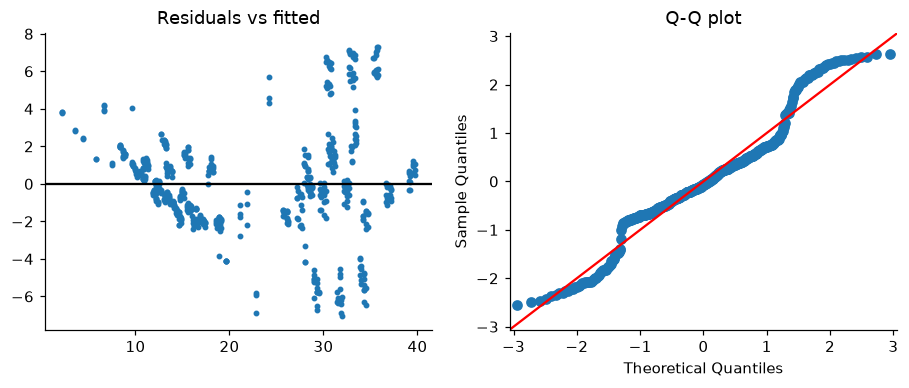

In [18]:
shapiro_test_p_value = stats.shapiro(best_ols_model.resid).pvalue
print("Shapiro p =", shapiro_test_p_value)

breusch_pagan_p_value = het_breuschpagan(best_ols_model.resid, best_ols_model.model.exog)[1]
print("Breusch-Pagan p =", breusch_pagan_p_value)

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 3.5))

axes[0].scatter(best_ols_model.fittedvalues, best_ols_model.resid, s = 8)
axes[0].axhline(y = 0, color = "k")
axes[0].set_title("Residuals vs fitted")

sm.qqplot(best_ols_model.resid, line = "45", fit = True, ax = axes[1])
axes[1].set_title("Q-Q plot")

fig.savefig("figures/04_ols_diagnostics.png")
plt.show()


In [19]:
def create_interaction_preprocessing_pipeline():
    return Pipeline(
        steps = [
            ("base_preprocessing", create_preprocessing_pipeline()),
            ("interaction_features", PolynomialFeatures(degree = 2, include_bias = False))
        ]
    )

alpha_values = np.logspace(start = -4, stop = 3, num = 60)
model_candidates = {
    "OLS": Pipeline(
        steps = [
            ("preprocessing", create_preprocessing_pipeline()), 
            ("model", LinearRegression())
        ]
    ),
    "OLS + interactions": Pipeline(
        steps = [
            ("preprocessing", create_interaction_preprocessing_pipeline()), 
            ("model", LinearRegression())
        ]
    ),
    "Ridge": Pipeline(
        steps = [
            ("preprocessing", create_interaction_preprocessing_pipeline()), 
            ("model", RidgeCV(alphas=alpha_values))
        ]
    ),
    "Lasso": Pipeline(
        steps = [
            ("preprocessing", create_interaction_preprocessing_pipeline()), 
            ("model", LassoCV(alphas=alpha_values, max_iter=50_000))
        ]
    ),
    "Random Forest": Pipeline(
        steps = [
            ("preprocessing", create_preprocessing_pipeline()),
            ("model", RandomForestRegressor(n_estimators = 500, random_state = SEED, n_jobs = -1))
        ]
    ),
    "Gradient Boosting": Pipeline(
        steps = [
            ("preprocessing", create_preprocessing_pipeline()),
            ("model", GradientBoostingRegressor(random_state = SEED))
        ]
    ),
}

cross_validation_strategy = RepeatedKFold(n_splits = 10, n_repeats = 3, random_state = SEED)
cross_validation_records = []

for target_variable in TARGETS:
    for model_name, pipeline in model_candidates.items():
        validation_scores = cross_validate(
            estimator = pipeline, 
            X = X_tr, 
            y = Y_tr[target_variable], 
            cv = cross_validation_strategy, 
            n_jobs = -1,
            scoring=["neg_root_mean_squared_error", "r2"]
        )
        
        mean_rmse = -validation_scores["test_neg_root_mean_squared_error"].mean()
        mean_r2 = validation_scores["test_r2"].mean()
        
        cross_validation_records.append([target_variable, model_name, mean_rmse, mean_r2])

cv_results_table = pd.DataFrame(
    cross_validation_records, 
    columns = ["target", "model", "CV_RMSE", "CV_R2"]
)
cv_results_table.to_csv("outputs/cv_comparison.csv", index = False)

pivoted_rmse_summary = cv_results_table.pivot(
    index = "model", 
    columns = "target", 
    values = "CV_RMSE"
).round(2)

print(pivoted_rmse_summary)

target              cooling_load  heating_load
model                                         
Gradient Boosting           1.64          0.50
Lasso                       1.86          0.87
OLS                         3.22          2.81
OLS + interactions          1.57          0.47
Random Forest               1.92          0.56
Ridge                       1.83          0.82
